# 04. Forêt aléatoire

## Préparation

In [1]:
import sys
sys.path.append("..")
import pandas as pd

import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, confusion_matrix
from src.data import X_train, X_test, y_train, y_test
from src.preprocessing import prepro
from src.evaluation import cv

Forêt aléatoire

In [7]:
from sklearn.ensemble import RandomForestClassifier

pip_rf = Pipeline([
    ("prétraitement", prepro),
    ("model", RandomForestClassifier(
        n_estimators=300,            # nombre d'arbres : fixé, pas cherché
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )),
])

grid_rf = {
    "model__max_depth":        [3, 5, 7],   # profondeur des arbres (None = illimitée)
    "model__min_samples_leaf": [1, 5, 10],     # patients minimum par feuille
}

clf_rf = GridSearchCV(pip_rf, grid_rf, cv=cv, scoring="f1_macro")

resultats_rf = cross_validate(
    clf_rf, X_train, y_train, cv=cv,
    scoring=["f1_macro", "recall", "precision", "accuracy", "roc_auc"],
    return_estimator=True, n_jobs=-1
)

for m in ["f1_macro", "recall", "precision", "accuracy", "roc_auc"]:
    v = resultats_rf[f"test_{m}"]
    print(f"{m:10s} : {v.mean():.3f} ± {v.std():.3f}")

for i, e in enumerate(resultats_rf["estimator"], 1):
    print(f"tour {i} : {e.best_params_}  (interne {e.best_score_:.3f} → externe {resultats_rf['test_f1_macro'][i-1]:.3f})")

f1_macro   : 0.414 ± 0.016
recall     : 0.445 ± 0.042
precision  : 0.381 ± 0.006
accuracy   : 0.415 ± 0.016
roc_auc    : 0.435 ± 0.044
tour 1 : {'model__max_depth': 5, 'model__min_samples_leaf': 10}  (interne 0.482 → externe 0.417)
tour 2 : {'model__max_depth': 7, 'model__min_samples_leaf': 10}  (interne 0.460 → externe 0.421)
tour 3 : {'model__max_depth': 7, 'model__min_samples_leaf': 5}  (interne 0.441 → externe 0.382)
tour 4 : {'model__max_depth': 3, 'model__min_samples_leaf': 5}  (interne 0.477 → externe 0.426)
tour 5 : {'model__max_depth': 5, 'model__min_samples_leaf': 10}  (interne 0.515 → externe 0.426)


0.41714285714285715


<Axes: >

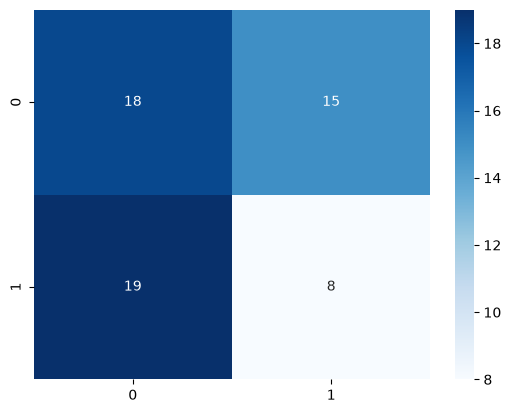

In [8]:
rfc = Pipeline([
    ("prétraitement", prepro),
    ("model", RandomForestClassifier(max_depth=5, n_estimators=300, class_weight="balanced", min_samples_leaf=10, random_state=42)),
])

rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)
score = f1_score(y_test, y_pred, average="macro")
print(score)
confusion_matrix_rfc = confusion_matrix(y_test, y_pred)
sns.heatmap(confusion_matrix_rfc, annot=True, cmap="Blues", fmt="g", annot_kws={"size": 10})


In [9]:
pd.DataFrame(resultats_rf).drop(columns="estimator").to_csv("../results/ranfo.csv", index=False)